# Câu d: Vẽ đồ thị phân tán CO, độ ẩm, nhiệt độ theo minutes

Phần 1 – Bài 2 (trang 30): Tiền xử lý dữ liệu môi trường nhà xưởng `tb_tracking.xlsx`

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
df = pd.read_excel(DATA + 'tb_tracking.xlsx', header=None)
# Cuối file có 1 dòng trống và 3 dòng thống kê (min, max, trung bình) -> bỏ
blank = df[df.isnull().all(axis=1)].index
if len(blank):
    df = df.loc[:blank[0] - 1]
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['id'] = df['id'].astype(int)
df['device_id'] = df['device_id'].astype(int)
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].reset_index(drop=True)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

---
## Thực hiện yêu cầu

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


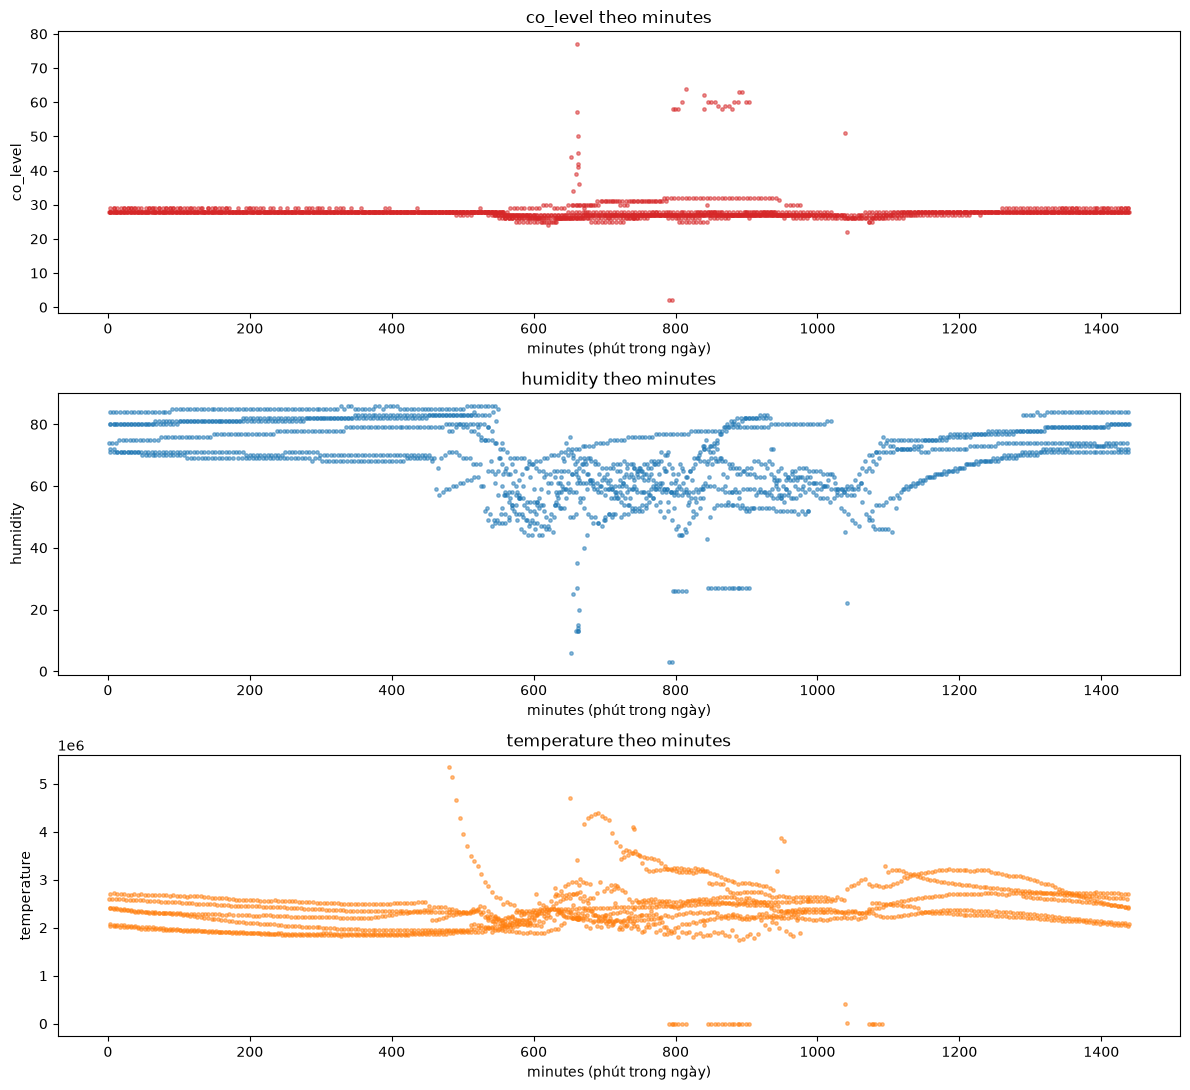

In [4]:
print(SV)
fig, axes = plt.subplots(3, 1, figsize=(12, 11))
for ax, col, color in zip(axes, ['co_level', 'humidity', 'temperature'], ['tab:red', 'tab:blue', 'tab:orange']):
    ax.scatter(df['minutes'], df[col], s=6, alpha=.5, color=color)
    ax.set_xlabel('minutes (phút trong ngày)')
    ax.set_ylabel(col)
    ax.set_title(f'{col} theo minutes')
plt.tight_layout()
plt.show()

In [5]:
df[['co_level', 'humidity', 'temperature']].describe()

,co_level,humidity,temperature
count,1917.000000,1917.000000,1.917000e+03
mean,28.190662,68.992697,2.358965e+06
std,3.997557,12.033094,4.951416e+05
min,2.000000,3.000000,0.000000e+00
25%,27.000000,61.000000,2.124650e+06
50%,28.000000,70.000000,2.331120e+06
75%,28.000000,79.000000,2.570550e+06
max,77.000000,86.000000,5.340310e+06


In [6]:
df['device_id'].value_counts()

device_id
99005    1723
0         192
1           2
Name: count, dtype: int64

**Nhận xét:**

- `co_level` gần như ổn định quanh 27–29 suốt cả ngày; chỉ trong khoảng 600–900 phút (10h–15h) có vài điểm tăng vọt lên 40–77, có thể là lúc nhà xưởng hoạt động mạnh.
- `humidity` cao (≈70–85) vào ban đêm và sáng sớm, giảm xuống ≈45–65 trong khoảng 550–1.100 phút (≈9h–18h), rồi tăng trở lại vào buổi tối: đúng chu kỳ ngày đêm.
- `temperature` có giá trị rất lớn (≈2.000.000) nên không phải độ C. Kết hợp với việc `co_level` có giá trị ≈28 giống nhiệt độ, có thể thứ tự cột trong đề không khớp với dữ liệu, hoặc cảm biến ghi giá trị thô chưa quy đổi.
- Có một số điểm bất thường: `temperature` = 0, `humidity` < 30 và `co_level` tăng vọt, đa số đến từ thiết bị 99005 trong khoảng 10h–18h; ngoài ra 2 dòng của thiết bị `device_id = 1` có giá trị cố định 2, 3, 4 giống dữ liệu chạy thử. Các điểm này cần được xử lý như nhiễu trước khi phân tích tiếp.